---
title: "3.3.b Amenaza por erosión de orillas y dinámica fluvial"
short_title: "b. Amenaza"
subtitle: "Migración del cauce, erosión y sedimentación frente a Leticia, 1987–2024"
description: "Análisis de la dinámica del río Amazonas frente a Leticia con compuestos Landsat de aguas bajas y JRC Global Surface Water."
keywords: [erosión, sedimentación, dinámica fluvial, Landsat, MNDWI, Global Surface Water, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/33_erosion/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El Amazonas es un río de cauces múltiples que **erosiona su orilla cóncava y deposita sedimento en la convexa**.
Las islas se forman, migran y desaparecen en pocas décadas. Frente a Leticia, la isla de Santa Rosa surgió hace
unos 50 años por acumulación de sedimentos y el flujo se ha desplazado hacia el brazo peruano: según estudios de
la Universidad Nacional, la fracción del caudal que pasa por el lado colombiano bajó de ~30 % en 1993 a ~19,5 %
en 2025 [@rtvc2025sedimentacion]. Río abajo, en Puerto Nariño, la socavación destruyó el muelle en 2020
[@pigcct2022amazonas]. Este cuaderno mide esa dinámica con imágenes de satélite.

In [2]:
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import aoi, espacial, exposicion, fuentes, viz
from leticia.config import parametros

pe = parametros()["erosion"]
urbana = aoi.area_urbana()
PIX_HA = (0.0003 * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4   # área de un píxel de 0,0003° en ha


def agua_anio(anio):
    ds = espacial.compuesto_landsat(anio, pe["meses_aguas_bajas"], ventana_anios=1 if anio < 2000 else 0)
    return (espacial.mndwi(ds) > pe["umbral_mndwi"]).rio.write_crs(4326), ds.attrs["escenas"]

## 1. El cauce en aguas bajas: 1987, 2001, 2013 y 2024

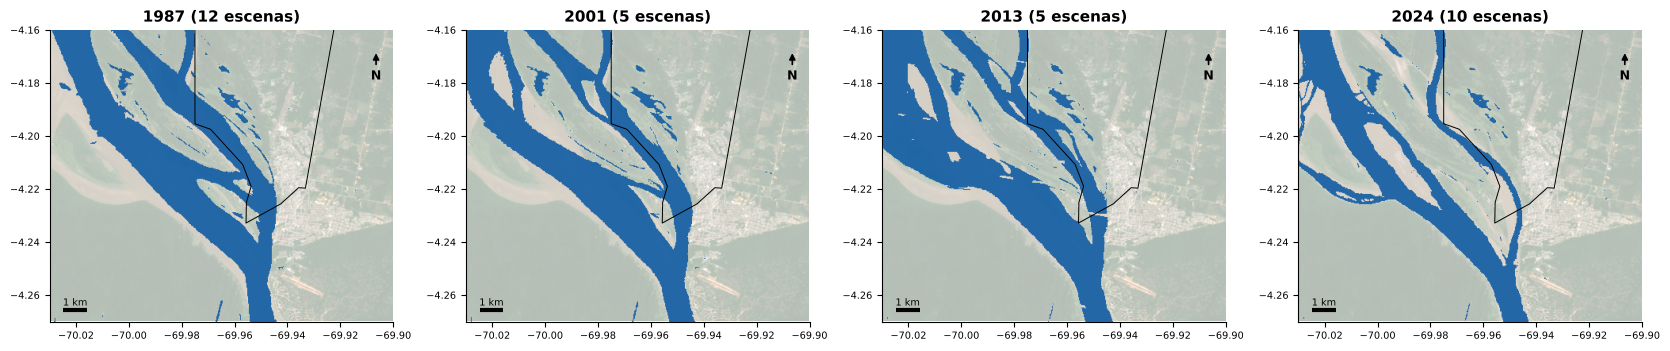

In [3]:
anios = pe["anios_comparacion"]
mascaras, escenas = {}, {}
for a in anios:
    mascaras[a], escenas[a] = agua_anio(a)
fig, ax = plt.subplots(1, len(anios), figsize=(4.2 * len(anios), 4.4))
for a, anio in zip(ax, anios):
    viz.fondo(a, "bbox_rio", alfa=0.35)
    m = mascaras[anio]
    a.imshow(np.where(m.values, 1.0, np.nan), extent=(float(m.x.min()), float(m.x.max()), float(m.y.min()), float(m.y.max())),
             cmap="Blues", vmin=0, vmax=1.2, zorder=2, alpha=0.9)
    urbana.to_crs(4326).boundary.plot(ax=a, color="k", lw=0.7, zorder=3)
    viz.marco(a, "bbox_rio", f"{anio} ({escenas[anio]} escenas)")
fig.tight_layout()

In [4]:
viz.pie(viz.nota_fuente("landsat") + " Agua: MNDWI > 0 (Xu, 2006) en la mediana de agosto–noviembre; mapa base Sentinel-2.")

*Fuente: USGS / NASA (Microsoft Planetary Computer) — Landsat Collection 2 Level-2 (reflectancia y temperatura de superficie). Agua: MNDWI > 0 (Xu, 2006) en la mediana de agosto–noviembre; mapa base Sentinel-2.*

## 2. Erosión y sedimentación entre 1987 y 2024

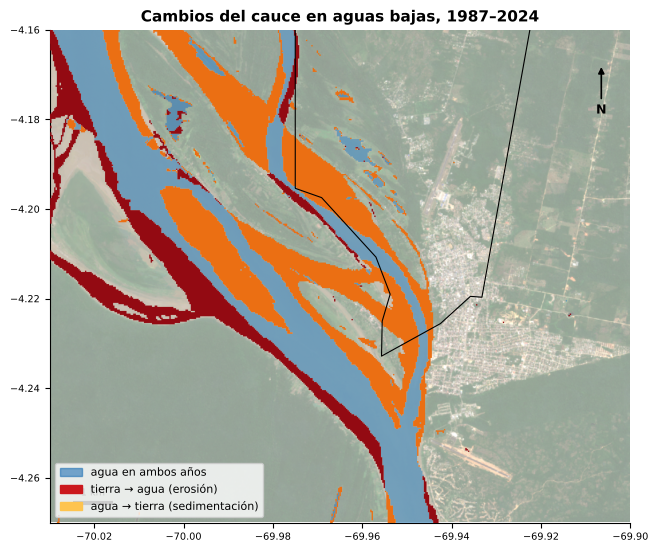

In [5]:
a0, a1 = anios[0], anios[-1]
m0 = mascaras[a0].reindex_like(mascaras[a1], method="nearest")
m1 = mascaras[a1]
erosion = (~m0.astype(bool)) & m1.astype(bool)      # tierra que pasó a agua
deposito = m0.astype(bool) & (~m1.astype(bool))      # agua que pasó a tierra (islas, playas, bancos)
fig, ax = plt.subplots(figsize=(8, 6.4))
viz.fondo(ax, "bbox_rio", alfa=0.5)
ext = (float(m1.x.min()), float(m1.x.max()), float(m1.y.min()), float(m1.y.max()))
ax.imshow(np.where(m0.values & m1.values, 1.0, np.nan), extent=ext, cmap="Blues", vmin=0, vmax=1.5, zorder=2, alpha=0.6)
ax.imshow(np.where(erosion.values, 1.0, np.nan), extent=ext, cmap="Reds", vmin=0, vmax=1.1, zorder=3)
ax.imshow(np.where(deposito.values, 1.0, np.nan), extent=ext, cmap="YlOrBr", vmin=0, vmax=1.6, zorder=3)
urbana.to_crs(4326).boundary.plot(ax=ax, color="k", lw=0.8, zorder=4)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#2171b5", alpha=0.6, label="agua en ambos años"), Patch(color="#cb181d", label=f"tierra → agua (erosión)"),
                   Patch(color="#fec44f", label="agua → tierra (sedimentación)")], loc="lower left", fontsize=8, frameon=True)
viz.marco(ax, "bbox_rio", f"Cambios del cauce en aguas bajas, {a0}–{a1}")

In [6]:
b = fuentes.bbox("bbox_rio")
sel = lambda da: da.sel(x=slice(b[0], b[2]), y=slice(b[3], b[1]))
res = pd.Series({"erosión (ha)": float(sel(erosion).sum()) * PIX_HA, "sedimentación (ha)": float(sel(deposito).sum()) * PIX_HA,
                 f"agua en aguas bajas {a0} (ha)": float(sel(m0).sum()) * PIX_HA, f"agua en aguas bajas {a1} (ha)": float(sel(m1).sum()) * PIX_HA})
display(res.round(0).to_frame("tramo frente a Leticia"))

,tramo frente a Leticia
erosión (ha),800.00
sedimentación (ha),"1,691.00"
agua en aguas bajas 1987 (ha),"3,497.00"
agua en aguas bajas 2024 (ha),"2,607.00"


:::{note} Nivel del río y cambio del cauce
Comparar dos años de aguas bajas mezcla dos efectos: el cambio de forma del cauce y la diferencia de nivel
(2024 fue la vaciante más baja del registro, así que aparecen más playas). Por eso el análisis se complementa con
las **transiciones** del JRC, que comparan la frecuencia del agua en 1984–1999 y 2000–2021 y no dependen de un
solo año.
:::

## 3. Transiciones del agua superficial, 1984–2021 (JRC)

,ha
permanente,"2,334.00"
nueva estacional,853.00
nueva permanente,641.00
permanente perdida,461.00
estacional perdida,381.00
permanente → estacional,364.00
estacional efímera,155.00
permanente efímera,136.00
estacional,88.00
estacional → permanente,45.00


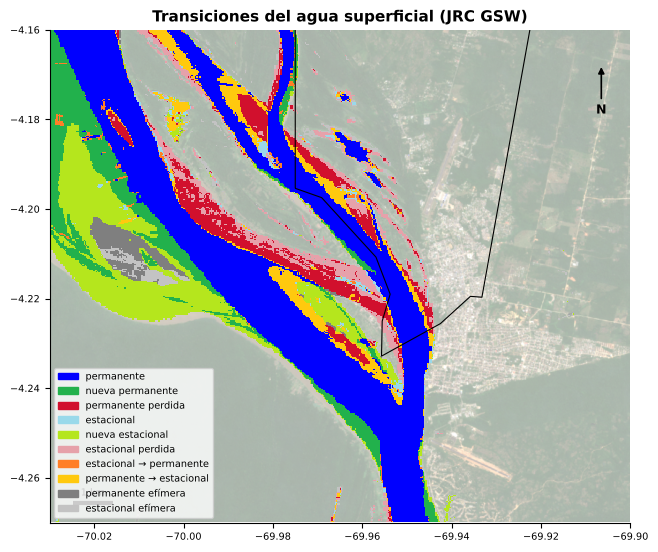

In [7]:
tr = fuentes.raster_estatico("jrc-gsw", "transitions")
CLASES = {1: ("permanente", "#0000ff"), 2: ("nueva permanente", "#22b14c"), 3: ("permanente perdida", "#d1102d"),
          4: ("estacional", "#99d9ea"), 5: ("nueva estacional", "#b5e61d"), 6: ("estacional perdida", "#e6a1aa"),
          7: ("estacional → permanente", "#ff7f27"), 8: ("permanente → estacional", "#ffc90e"),
          9: ("permanente efímera", "#7f7f7f"), 10: ("estacional efímera", "#c3c3c3")}
from matplotlib.colors import ListedColormap, BoundaryNorm
cods = list(CLASES)
cmap = ListedColormap([CLASES[k][1] for k in cods])
norm = BoundaryNorm(np.arange(0.5, 11.5), cmap.N)
t = sel(tr)
fig, ax = plt.subplots(figsize=(8, 6.4))
viz.fondo(ax, "bbox_rio", alfa=0.4)
ax.imshow(np.where(t.values > 0, t.values, np.nan), extent=(float(t.x.min()), float(t.x.max()), float(t.y.min()), float(t.y.max())),
          cmap=cmap, norm=norm, interpolation="nearest", zorder=2)
urbana.to_crs(4326).boundary.plot(ax=ax, color="k", lw=0.8, zorder=3)
ax.legend(handles=[Patch(color=CLASES[k][1], label=CLASES[k][0]) for k in cods if (t.values == k).any()], loc="lower left", fontsize=7, frameon=True)
viz.marco(ax, "bbox_rio", "Transiciones del agua superficial (JRC GSW)")
px_tr = (float(abs(t.x[1] - t.x[0])) * 111320) ** 2 * np.cos(np.radians(4.2)) / 1e4
conteo = pd.Series(t.values.ravel()).value_counts()
display((conteo.rename(index={k: v[0] for k, v in CLASES.items()}).drop(0, errors="ignore") * px_tr).round(0).to_frame("ha").head(10))

In [8]:
viz.pie(viz.nota_fuente("agua_superficial_jrc") + " Pekel et al. (2016).")

*Fuente: JRC – Global Surface Water (Pekel et al. 2016) — occurrence, seasonality, transitions, extent. Pekel et al. (2016).*

**Lectura.** Las clases **«permanente perdida»** (rojo) y **«nueva permanente»** (verde) marcan dónde el cauce
migró: el río abandonó unas zonas y ocupó otras. Las **«nuevas estacionales»** suelen ser playas y bancos de
arena que emergen en aguas bajas. Frente a Leticia, la acumulación de sedimento en el brazo colombiano y la
erosión en la margen opuesta son consistentes con el desplazamiento del flujo hacia el brazo peruano
[@rtvc2025sedimentacion].

## 4. Tasas de erosión y acreción por tramo (REAL)

El conjunto REAL de Langhorst y Pavelsky estima cuánto retrocede (erosión) y cuánto avanza (acreción) la orilla por
año en cada tramo de unos 10 km de los ríos de más de 150 m de ancho del mundo. Usa hasta 20 años de clasificaciones
de agua de Landsat y propaga el error de esa clasificación para estimar el ruido de cada tasa [@langhorst2023real].
Es una medida independiente de la de las secciones anteriores y permite comparar el Amazonas frente a Leticia con
otros ríos del mundo.

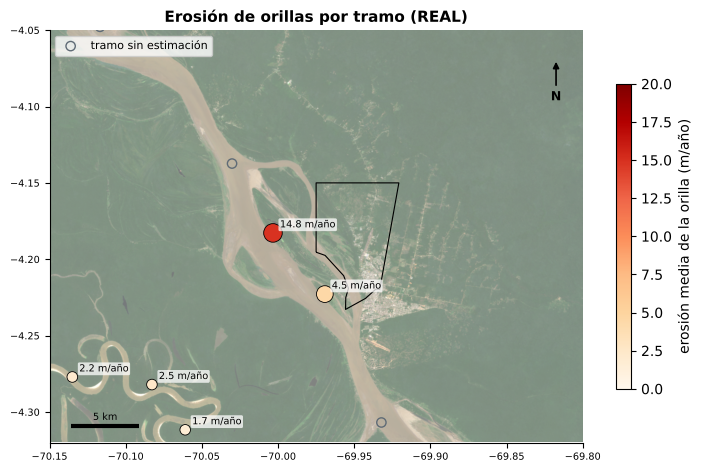

In [9]:
real = fuentes.erosion_real()
con = real.dropna(subset=["erosion_m_anio"])
sin = real[real["erosion_m_anio"].isna()]
fig, ax = plt.subplots(figsize=(8.6, 6.6))
viz.fondo(ax, "bbox_regional", alfa=0.6)
ax.scatter(sin["lon"], sin["lat"], s=45, facecolor="none", edgecolor=viz.GRIS, lw=1, zorder=3, label="tramo sin estimación")
sc = ax.scatter(con["lon"], con["lat"], c=con["erosion_m_anio"], cmap="OrRd", vmin=0, vmax=20, s=40 + con["ancho_m"] / 25,
                edgecolor="k", lw=0.6, zorder=4)
for _, r_ in con.iterrows():
    ax.annotate(f"{r_['erosion_m_anio']:.1f} m/año", (r_["lon"], r_["lat"]), xytext=(5, 4), textcoords="offset points", fontsize=7,
                zorder=5, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
urbana.to_crs(4326).boundary.plot(ax=ax, color="k", lw=0.8, zorder=3)
fig.colorbar(sc, ax=ax, shrink=0.6, label="erosión media de la orilla (m/año)")
ax.legend(loc="upper left", fontsize=8, frameon=True)
viz.marco(ax, "bbox_regional", "Erosión de orillas por tramo (REAL)")

In [10]:
viz.pie(viz.nota_fuente("erosion_real") + " Centro de cada tramo de SWORD; el tamaño del punto es proporcional al ancho del río.")

*Fuente: Langhorst y Pavelsky (2023) – Riverbank Erosion and Accretion from Landsat (REAL) — REAL v0.1: tasas medias y máximas (m/año) por tramo de SWORD, Landsat 2000–2020. Centro de cada tramo de SWORD; el tamaño del punto es proporcional al ancho del río.*

In [11]:
centro = gpd.GeoSeries(gpd.points_from_xy([viz.centro()[0]], [viz.centro()[1]]), crs=4326).to_crs(aoi.crs()).iloc[0]
tabla = con.assign(distancia_km=con.to_crs(aoi.crs()).distance(centro) / 1000, rio=con["rio"].fillna("sin nombre en SWORD"))
tabla = tabla.sort_values("lon")[["rio", "distancia_km", "ancho_m", "erosion_m_anio", "erosion_max_m_anio", "acrecion_m_anio",
                                  "ruido_erosion_m_anio", "anio_inicial", "anio_final"]]
tabla.columns = ["río (SWORD)", "distancia a Leticia (km)", "ancho (m)", "erosión media (m/año)", "erosión máxima (m/año)",
                 "acreción media (m/año)", "ruido de la erosión (m/año)", "año inicial", "año final"]
display(tabla.set_index(tabla.index.astype(str)).round(1))
ancho = con[con["ancho_m"] > 1000]
display(Markdown(f"Tramos del cauce principal (más de 1 km de ancho) con estimación: **{len(ancho)}**; erosión media entre "
                 f"**{ancho['erosion_m_anio'].min():.1f} y {ancho['erosion_m_anio'].max():.1f} m/año** (mediana {ancho['erosion_m_anio'].median():.1f}). "
                 f"Tramos sin estimación en la extensión: {len(sin)} de {len(real)}."))

,río (SWORD),distancia a Leticia (km),ancho (m),erosión media (m/año),erosión máxima (m/año),acreción media (m/año),ruido de la erosión (m/año),año inicial,año final
7,Javary River,38.80,284.00,1.20,6.90,2.00,0.00,"2,002.00","2,019.00"
6,Javary River,34.30,298.00,1.10,4.10,1.50,0.00,"2,002.00","2,019.00"
24,sin nombre en SWORD,49.50,"2,174.00",7.70,42.70,4.90,0.30,"2,002.00","2,017.00"
5,Javary River,29.40,429.00,2.20,5.30,2.80,0.10,"2,002.00","2,019.00"
9,Javary River,22.70,468.00,2.20,5.90,2.50,0.10,"2,002.00","2,018.00"
10,Javary River,17.60,458.00,2.50,5.50,2.90,0.10,"2,002.00","2,019.00"
12,Javary River,17.30,439.00,1.70,5.60,1.60,0.10,"2,000.00","2,018.00"
23,sin nombre en SWORD,7.70,"3,476.00",14.80,49.10,20.40,0.70,"2,002.00","2,017.00"
11,Javary River,16.70,"2,444.50",2.30,42.40,39.00,0.10,"2,002.00","2,019.00"
22,sin nombre en SWORD,3.40,"2,636.50",4.50,37.10,37.20,0.20,"2,002.00","2,017.00"


Tramos del cauce principal (más de 1 km de ancho) con estimación: **4**; erosión media entre **2.3 y 14.8 m/año** (mediana 6.1). Tramos sin estimación en la extensión: 17 de 27.

**Lectura.** En los tramos del cauce principal cercanos a Leticia la orilla retrocede en promedio entre 2 y 15 m por
año, hasta diez veces la mediana mundial de 1,5 m/año que Langhorst y Pavelsky encontraron para ríos de más de
150 m de ancho [@langhorst2023real]; en sitios puntuales el retroceso máximo supera los 35 m/año. En el Yavarí,
mucho más angosto, la erosión media es de 1 a 2,5 m/año. El ruido
estimado (menos de 1 m/año) es pequeño frente a esas tasas. En el tramo junto a la ciudad la **acreción supera a
la erosión**: la orilla gana más terreno del que pierde. Eso coincide con lo que Villadiego-Rojas et al. muestran
entre Nazareth y Leticia con un modelo numérico validado con imágenes: erosión de la margen derecha (peruana),
sedimentación y estrechamiento del brazo izquierdo (colombiano) y aparición de bancos de arena; si el proceso
continúa, el brazo colombiano podría cerrarse [@villadiego2023]. Los tramos frente al malecón y aguas abajo, con
islas y varios cauces, no tienen estimación en REAL; para ellos sirven el análisis Landsat de las secciones 1–3 y
el monitoreo local. Los nombres de los ríos vienen de la base SWORD y pueden no coincidir con los locales.

:::{note} Tierras caídas
En la Amazonía brasileña se discute si las *terras caídas*, el colapso súbito de barrancos, son una forma de
erosión fluvial o un fenómeno distinto [@bandeira2018]. Las tasas de REAL miden el retroceso promedio de la
orilla entre dos fechas y no registran esos colapsos puntuales, que son los que destruyen viviendas y muelles.
:::